# UTS Machine Learning — Task 1: Delivery Time Regression

**Objective:** estimate package delivery duration (`durasi_jam`) using a median prediction (P50) and an upper-quantile prediction (P90).

**Data:** `regresi_train.csv.gz`, `regresi_test.csv.gz`, and `kamus_data.md` from the supplied dataset archive.

**Reproducibility:** run this notebook from top to bottom in Google Colab. The setup cells mount Google Drive and extract `data_uts_ml.zip` from `MyDrive/UTS_ML/`.

**Important evaluation note:** validation is chronological (January–June 2025 training; July–August 2025 validation). The June-derived additive calibration was tested for transfer and rejected because it worsened July–August validation metrics. The production models are refit on all supplied training data.


# TASK 1 — REGRESSION: DELIVERY TIME ESTIMATION

Notebook workflow:
1. Environment setup, Drive mount, and dataset extraction
2. Data loading, dictionary review, and data-quality audit
3. Feature availability, leakage, and temporal diagnostics
4. Chronological validation and baseline quantile predictions
5. CatBoost P50 and P90 model training
6. Early stopping and final temporal evaluation
7. Calibration-transfer experiment and decision
8. Production refit on all training data
9. Test predictions and submission validation

See the project README and final report for a consolidated summary.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 1. ENVIRONMENT AND REPRODUCIBILITY

import os
import zipfile
import random
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

warnings.filterwarnings("default")

# Plot settings
sns.set_theme(style="whitegrid")

print("Environment successfully initialized.")
print("Random seed:", SEED)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Environment successfully initialized.
Random seed: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
# 2. DATASET EXTRACTION

ZIP_PATH = "/content/drive/MyDrive/UTS_ML/data_uts_ml.zip"
DATA_DIR = "/content/uts_ml_data"

assert os.path.exists(ZIP_PATH), "ZIP file not found!"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    zip_ref.extractall(DATA_DIR)

print("Extraction completed.")

print("\nFiles available:")

for filename in sorted(os.listdir(DATA_DIR)):
    filepath = os.path.join(DATA_DIR, filename)

    if os.path.isfile(filepath):
        print(
            filename,
            "|",
            round(os.path.getsize(filepath) / (1024**2), 2),
            "MB"
        )

Extraction completed.

Files available:
clustering.csv.gz | 14.96 MB
kamus_data.md | 0.0 MB
klasifikasi_test.csv.gz | 17.39 MB
klasifikasi_train.csv.gz | 65.42 MB
regresi_test.csv.gz | 8.3 MB
regresi_train.csv.gz | 35.35 MB


In [4]:
# 1. LOAD REGRESSION DATA

TRAIN_PATH = os.path.join(
    DATA_DIR,
    "regresi_train.csv.gz"
)

TEST_PATH = os.path.join(
    DATA_DIR,
    "regresi_test.csv.gz"
)

DICTIONARY_PATH = os.path.join(
    DATA_DIR,
    "kamus_data.md"
)

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

with open(DICTIONARY_PATH, "r", encoding="utf-8") as file:
    dictionary = file.read()

print("Training dataset loaded.")
print("Testing dataset loaded.")
print("Data dictionary loaded.")

Training dataset loaded.
Testing dataset loaded.
Data dictionary loaded.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
# DATASET INTEGRITY CHECK

TARGET = "durasi_jam"
ID_COL = "id_paket"

print("TRAINING SHAPE:", train.shape)
print("TESTING SHAPE:", test.shape)

print("\nTarget availability:")

print("Target in training:", TARGET in train.columns)
print("Target in testing:", TARGET in test.columns)

print("\nID availability:")

print("ID in training:", ID_COL in train.columns)
print("ID in testing:", ID_COL in test.columns)

# Check duplicate column names
print("\nDuplicate column names:")

print("Train:", train.columns.duplicated().sum())
print("Test:", test.columns.duplicated().sum())

# Check column consistency
train_features = set(train.columns) - {TARGET}
test_features = set(test.columns)

print("\nColumn consistency:")

print("Same feature sets:", train_features == test_features)

print(
    "Features missing from test:",
    train_features - test_features
)

print(
    "Unexpected test features:",
    test_features - train_features
)

# Check ID uniqueness
print("\nID uniqueness:")

print("Train IDs unique:", train[ID_COL].is_unique)
print("Test IDs unique:", test[ID_COL].is_unique)

# Check train-test ID overlap
overlap = set(train[ID_COL]) & set(test[ID_COL])

print("Train-test ID overlap:", len(overlap))

TRAINING SHAPE: (250000, 77)
TESTING SHAPE: (60000, 76)

Target availability:
Target in training: True
Target in testing: False

ID availability:
ID in training: True
ID in testing: True

Duplicate column names:
Train: 0
Test: 0

Column consistency:
Same feature sets: True
Features missing from test: set()
Unexpected test features: set()

ID uniqueness:
Train IDs unique: True
Test IDs unique: True
Train-test ID overlap: 0


In [6]:
# DATA DICTIONARY

print(dictionary)

# Kamus data UTS Machine Learning

Data latih regresi dan klasifikasi ditarik pada **31 Agustus 2025**. Data uji mencakup
1 September sampai 31 Oktober 2025. Semua kelompok menerima data yang sama.

## Tugas 1: regresi_train.csv.gz dan regresi_test.csv.gz

Satu baris per paket. Prediksi dibuat saat paket diambil kurir.

| Kolom | Keterangan |
| --- | --- |
| id_paket | ID paket |
| tgl_pickup, jam_pickup | Tanggal dan jam paket diambil kurir |
| layanan | Jenis layanan pengiriman |
| mitra_kurir | Mitra kurir yang mengantar |
| hub_asal, kota_asal | Hub penyortiran dan kota asal |
| pulau_tujuan, kota_tujuan | Pulau dan kota tujuan |
| jarak_km | Jarak rute menurut sistem (km) |
| berat_kg | Berat yang dideklarasikan penjual (kg) |
| volume_liter, jumlah_item, nilai_barang | Volume, jumlah barang, dan nilai barang (rupiah) |
| asuransi, cod | 1 jika diasuransikan, 1 jika bayar di tempat |
| alamat_skor | Skor kelengkapan alamat penerima (0-1) |
| pengalaman_kurir_bulan | Pengalaman kur

In [7]:
# INITIAL DATA INSPECTION

print("TRAINING DATA – FIRST 5 ROWS")
display(train.head())

print("\nTESTING DATA – FIRST 5 ROWS")
display(test.head())

print("\nTRAINING COLUMN NAMES")

for i, col in enumerate(train.columns, start=1):
    print(f"{i:02d}. {col}")

TRAINING DATA – FIRST 5 ROWS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,berat_kg,volume_liter,jumlah_item,nilai_barang,asuransi,cod,alamat_skor,pengalaman_kurir_bulan,rating_penjual,umur_akun_penjual_hari,volume_penjual_30h,antrean_hub_asal,indeks_kemacetan,hujan_asal_mm,hujan_tujuan_mm,jumlah_scan,f01,f02,f03,f04,f05,f06,f07,f08,f09,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23,f24,f25,f26,f27,f28,f29,f30,f31,f32,f33,f34,f35,f36,f37,f38,f39,f40,f41,f42,f43,f44,f45,f46,f47,f48,f49,f50,durasi_jam
0,P24198861,2025-03-13,10,ekspres,K07,JKT,KA01,Jawa,KT099,1077.6,0.44,1.0,1,355000.0,0,0,0.894,14.6,4.56,367,134,9630,0.429,0.0,5.9,8,0.112,0.364,1.0,0.342,0.163,1.642,0.120,1.585,0.780,2.0,0.757,-1.180,0.768,3.941,0.0,2.0,0.139,-0.311,0.456,0.598,0.0,-0.411,-0.202,-0.372,0.452,0.553,0.0,-0.018,1.856,0.018,0.095,1.223,1.0,5.0,0.972,-0.860,0.107,0.472,1.0,1.0,0.039,0.683,0.644,3.957,1.0,3.0,-0.207,0.721,0.661,3.760,40.4
1,P44313480,2025-06-24,9,reguler,K05,SBY,KA09,Jawa,KT101,829.3,0.71,5.8,1,278000.0,0,0,0.854,40.0,4.53,712,64,1319,0.681,21.0,53.2,18,0.394,0.736,0.0,0.363,-0.381,-0.672,0.060,0.260,1.104,3.0,-1.004,0.848,1.206,0.541,0.0,4.0,0.252,0.102,0.688,2.323,0.0,-0.466,-0.212,-1.519,0.728,0.568,0.0,0.068,4.965,1.708,0.991,0.331,0.0,7.0,1.070,-0.941,0.967,0.556,0.0,3.0,0.686,-0.521,0.011,0.429,0.0,2.0,0.890,0.065,0.232,1.866,78.7
2,P18332724,2025-05-07,11,kargo,K03,JKT,KA02,Jawa,KT066,758.6,NaN,151.3,2,139000.0,0,0,0.792,4.2,4.51,251,104,46314,0.429,0.0,27.6,4,0.306,1.335,0.0,0.428,1.257,-0.776,0.944,0.594,1.117,2.0,0.379,-0.120,1.915,2.195,0.0,5.0,0.872,-0.480,0.298,5.651,1.0,-0.686,-0.444,-1.867,0.213,0.575,0.0,-0.077,1.197,0.778,0.412,0.842,0.0,0.0,1.045,-0.184,0.075,3.008,0.0,3.0,0.076,-1.004,0.506,0.795,0.0,2.0,-2.769,-1.031,0.777,2.809,101.3
3,P85422083,2025-05-19,14,ekspres,K03,MKS,KA28,Sulawesi,KT273,396.2,1.11,3.9,1,314000.0,0,1,0.443,6.0,4.62,295,215,237,0.403,0.0,0.0,8,0.206,0.405,0.0,-0.064,-0.410,-1.254,0.919,1.333,0.775,1.0,-0.054,-0.759,1.055,4.920,0.0,5.0,0.122,0.643,0.696,2.313,1.0,0.418,1.153,0.563,0.467,1.701,0.0,0.602,0.266,0.682,0.943,0.171,0.0,3.0,0.963,1.067,0.909,0.401,0.0,2.0,0.148,0.240,0.721,1.118,1.0,7.0,2.163,-1.766,0.275,1.498,60.3
4,P60211760,2025-04-29,7,kargo,K07,SMG,KA20,Jawa,KT066,254.6,NaN,348.0,6,1439000.0,1,1,0.707,5.7,4.76,383,497,342,0.578,0.0,11.3,11,0.519,1.236,1.0,-0.447,0.273,0.724,0.679,2.253,1.178,4.0,0.935,1.074,-0.423,0.641,0.0,4.0,0.000,1.754,0.480,0.532,0.0,-0.571,-0.591,0.832,0.172,2.539,0.0,0.089,-0.957,1.172,0.769,4.721,1.0,4.0,1.046,-0.907,0.136,2.809,0.0,2.0,0.062,0.287,0.734,1.899,0.0,4.0,0.203,-0.886,0.180,0.512,63.1



TESTING DATA – FIRST 5 ROWS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id_paket,tgl_pickup,jam_pickup,layanan,mitra_kurir,hub_asal,kota_asal,pulau_tujuan,kota_tujuan,jarak_km,berat_kg,volume_liter,jumlah_item,nilai_barang,asuransi,cod,alamat_skor,pengalaman_kurir_bulan,rating_penjual,umur_akun_penjual_hari,volume_penjual_30h,antrean_hub_asal,indeks_kemacetan,hujan_asal_mm,hujan_tujuan_mm,jumlah_scan,f01,f02,f03,f04,f05,f06,f07,f08,f09,f10,f11,f12,f13,f14,f15,f16,f17,f18,f19,f20,f21,f22,f23,f24,f25,f26,f27,f28,f29,f30,f31,f32,f33,f34,f35,f36,f37,f38,f39,f40,f41,f42,f43,f44,f45,f46,f47,f48,f49,f50
0,P83639399,2025-10-07,21,reguler,K01,JKT,KA04,Jawa,KT066,709.5,0.60,4.3,2,339000.0,0,0,0.735,10.4,4.57,537,256,4449,0.413,5.8,5.5,3,0.749,1.501,1.0,-0.342,-0.482,-2.067,0.436,0.315,1.062,2.0,0.435,-0.381,2.478,0.188,1.0,4.0,0.100,-0.476,0.466,6.593,1.0,-0.672,-0.659,-0.982,0.938,0.927,0.0,0.257,0.303,2.623,0.761,0.800,0.0,2.0,0.984,1.922,0.093,2.036,0.0,5.0,-0.010,-0.757,0.603,0.504,0.0,8.0,0.830,-2.848,0.074,1.524
1,P26553951,2025-09-11,12,hemat,K09,SBY,KA09,Sumatera,KT192,2197.0,1.59,5.9,1,226000.0,0,1,0.705,9.4,4.61,1018,898,22420,0.376,0.0,21.3,1,0.482,0.728,0.0,0.010,-0.211,0.224,0.471,3.159,1.122,5.0,0.634,-0.629,1.020,0.803,0.0,5.0,0.849,0.635,0.730,2.119,0.0,-0.973,-1.242,-0.997,0.740,1.029,0.0,0.219,-0.024,0.482,0.358,0.902,0.0,3.0,0.983,0.322,0.661,0.409,1.0,4.0,0.077,-0.210,0.590,2.276,1.0,3.0,-0.811,2.045,0.109,1.439
2,P32537117,2025-10-28,14,hemat,K03,SBY,KA11,Jawa,KT020,69.1,1.35,3.9,2,185000.0,0,1,0.950,2.1,4.58,1048,91,5415,0.330,6.5,0.0,1,0.480,0.492,0.0,0.236,0.777,1.258,0.394,0.217,0.613,5.0,0.454,-0.323,1.581,4.816,1.0,4.0,0.247,0.197,0.681,0.847,1.0,-0.517,0.048,0.782,0.179,2.187,0.0,0.026,0.446,0.763,0.876,2.040,0.0,4.0,1.048,0.270,0.431,4.506,0.0,5.0,-0.013,1.196,0.823,0.402,1.0,4.0,2.682,0.443,0.353,1.231
3,P28750760,2025-10-03,13,ekspres,K02,MKS,KA28,Jawa,KT088,1004.5,1.08,3.4,2,36000.0,0,0,0.811,6.2,4.71,343,1424,3441,0.206,2.0,88.3,1,0.038,1.974,0.0,1.408,1.977,-1.089,0.265,0.416,0.874,4.0,0.719,2.292,0.213,0.321,0.0,2.0,0.467,1.061,0.752,1.173,0.0,-0.617,0.459,-0.252,0.478,1.218,0.0,0.014,-2.416,1.379,0.135,0.162,0.0,2.0,1.112,-1.722,0.987,0.575,0.0,3.0,0.327,0.879,0.489,1.712,0.0,3.0,-0.865,1.986,0.046,1.014
4,P96580009,2025-09-08,15,ekspres,K07,JKT,KA02,Jawa,KT066,758.6,5.57,36.8,3,455000.0,0,0,0.628,9.2,4.74,950,223,424,0.446,0.0,0.0,1,0.071,0.471,0.0,-0.127,0.287,-0.996,0.223,0.806,1.368,3.0,0.950,0.210,1.767,0.234,0.0,2.0,0.326,-1.133,0.364,1.094,0.0,-0.620,-0.280,0.130,0.693,5.707,1.0,0.481,-0.557,2.081,0.277,4.619,1.0,5.0,1.438,0.696,0.240,0.460,0.0,5.0,0.033,1.743,0.485,0.377,1.0,1.0,-1.581,0.420,0.821,0.939



TRAINING COLUMN NAMES
01. id_paket
02. tgl_pickup
03. jam_pickup
04. layanan
05. mitra_kurir
06. hub_asal
07. kota_asal
08. pulau_tujuan
09. kota_tujuan
10. jarak_km
11. berat_kg
12. volume_liter
13. jumlah_item
14. nilai_barang
15. asuransi
16. cod
17. alamat_skor
18. pengalaman_kurir_bulan
19. rating_penjual
20. umur_akun_penjual_hari
21. volume_penjual_30h
22. antrean_hub_asal
23. indeks_kemacetan
24. hujan_asal_mm
25. hujan_tujuan_mm
26. jumlah_scan
27. f01
28. f02
29. f03
30. f04
31. f05
32. f06
33. f07
34. f08
35. f09
36. f10
37. f11
38. f12
39. f13
40. f14
41. f15
42. f16
43. f17
44. f18
45. f19
46. f20
47. f21
48. f22
49. f23
50. f24
51. f25
52. f26
53. f27
54. f28
55. f29
56. f30
57. f31
58. f32
59. f33
60. f34
61. f35
62. f36
63. f37
64. f38
65. f39
66. f40
67. f41
68. f42
69. f43
70. f44
71. f45
72. f46
73. f47
74. f48
75. f49
76. f50
77. durasi_jam


In [8]:
# MISSING VALUE AUDIT

def missing_value_audit(df, dataset_name):

    result = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": df.isna().mean() * 100
    })

    result = result[result["missing_count"] > 0]

    result = result.sort_values(
        "missing_percentage",
        ascending=False
    )

    print(f"\n{dataset_name}")
    print("Total rows:", len(df))
    print("Columns with missing values:", len(result))

    return result


missing_train = missing_value_audit(
    train,
    "TRAINING DATA"
)

missing_test = missing_value_audit(
    test,
    "TESTING DATA"
)

display(missing_train)
display(missing_test)


TRAINING DATA
Total rows: 250000
Columns with missing values: 1

TESTING DATA
Total rows: 60000
Columns with missing values: 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,missing_count,missing_percentage
berat_kg,13897,5.5588


,missing_count,missing_percentage
berat_kg,3265,5.441667


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


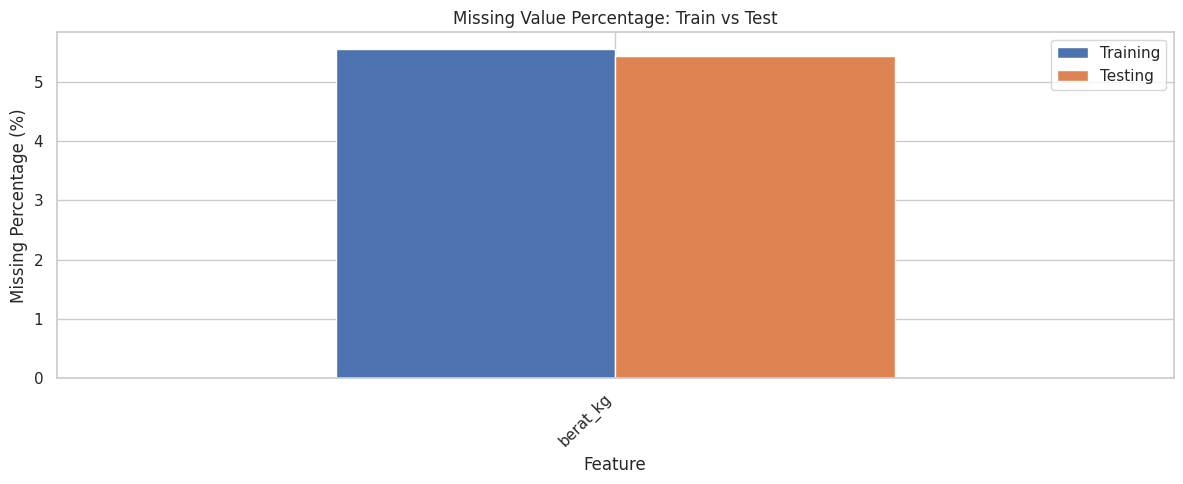

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
# MISSINGNESS VISUALIZATION

missing_combined = pd.DataFrame({
    "Training": train.isna().mean() * 100,
    "Testing": test.isna().mean() * 100
})

missing_combined = missing_combined[
    (missing_combined["Training"] > 0) |
    (missing_combined["Testing"] > 0)
]

missing_combined.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Missing Value Percentage: Train vs Test")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# TARGET QUALITY AUDIT

target = train["durasi_jam"]

target_summary = pd.Series({
    "Count": target.count(),
    "Missing": target.isna().sum(),
    "Unique values": target.nunique(),
    "Minimum": target.min(),
    "Maximum": target.max(),
    "Mean": target.mean(),
    "Median": target.median(),
    "Standard deviation": target.std(),
    "Q1": target.quantile(0.25),
    "Q3": target.quantile(0.75),
    "P90": target.quantile(0.90),
    "P95": target.quantile(0.95),
    "P99": target.quantile(0.99),
    "Negative values": (target < 0).sum(),
    "Zero values": (target == 0).sum()
})

display(target_summary.to_frame("Value"))

,Value
Count,250000.000000
Missing,0.000000
Unique values,3540.000000
Minimum,11.600000
Maximum,25452.000000
Mean,77.838195
Median,61.700000
Standard deviation,207.656270
Q1,45.600000
Q3,85.300000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


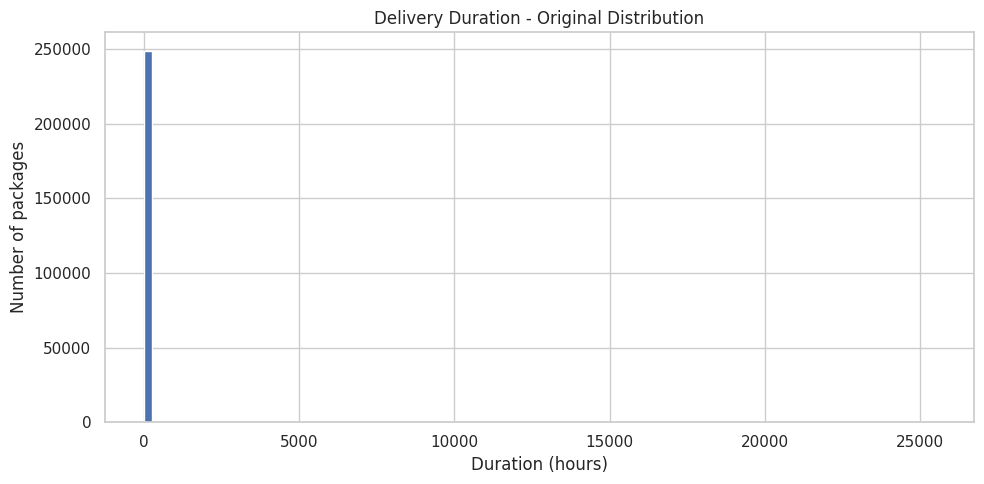

In [11]:
# ORIGINAL HISTOGRAM

plt.figure(figsize=(10, 5))

plt.hist(
    target.dropna(),
    bins=100
)

plt.title("Delivery Duration - Original Distribution")
plt.xlabel("Duration (hours)")
plt.ylabel("Number of packages")

plt.tight_layout()
plt.show()

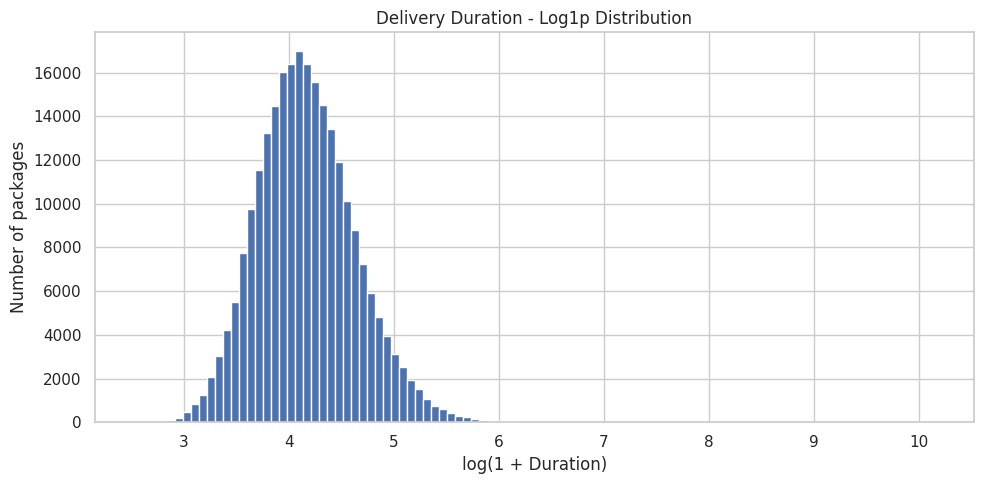

In [12]:
# LOG TRANSFORMED HISTOGRAM

plt.figure(figsize=(10, 5))

plt.hist(
    np.log1p(target.dropna()),
    bins=100
)

plt.title("Delivery Duration - Log1p Distribution")
plt.xlabel("log(1 + Duration)")
plt.ylabel("Number of packages")

plt.tight_layout()
plt.show()

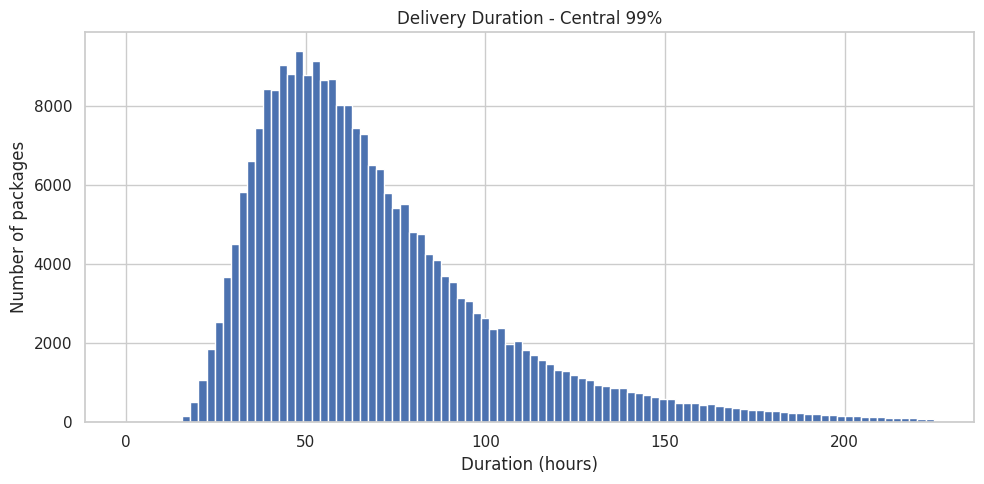

99th percentile: 224.70100000000093


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
# CENTRAL 99% HISTOGRAM

p99 = target.quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    target.dropna(),
    bins=100,
    range=(0, p99)
)

plt.title("Delivery Duration - Central 99%")
plt.xlabel("Duration (hours)")
plt.ylabel("Number of packages")

plt.tight_layout()
plt.show()

print("99th percentile:", p99)

In [14]:
# TARGET OUTLIER ANALYSIS

q1 = target.quantile(0.25)
q3 = target.quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

target_outliers = train[
    (target < lower_bound) |
    (target > upper_bound)
].copy()

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Outlier count:", len(target_outliers))

print(
    "Outlier percentage:",
    len(target_outliers) / len(train) * 100
)

display(
    target_outliers[
        [
            "id_paket",
            "tgl_pickup",
            "layanan",
            "pulau_tujuan",
            "mitra_kurir",
            "durasi_jam"
        ]
    ].sort_values(
        "durasi_jam",
        ascending=False
    ).head(20)
)

Q1: 45.6
Q3: 85.3
IQR: 39.699999999999996
Lower bound: -13.949999999999996
Upper bound: 144.85
Outlier count: 12763
Outlier percentage: 5.1052


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id_paket,tgl_pickup,layanan,pulau_tujuan,mitra_kurir,durasi_jam
84362,P40474529,2025-07-04,reguler,Jawa,K02,25452.0
108275,P62729634,2025-02-06,ekspres,Jawa,K03,25020.0
98789,P12077092,2025-03-03,hemat,Jawa,K03,16650.0
142557,P97171338,2025-01-16,hemat,Papua,K12,16284.0
62562,P34488358,2025-08-10,hemat,Kalimantan,K02,13914.0
63531,P51550495,2025-08-28,hemat,Jawa,K01,13812.0
207233,P30815212,2025-04-26,hemat,Jawa,K03,13746.0
205666,P76218261,2025-06-23,kargo,Papua,K01,13560.0
146636,P28725772,2025-07-26,hemat,Jawa,K07,13482.0
237355,P58123091,2025-08-13,hemat,Sulawesi,K06,12582.0


In [15]:
# DUPLICATE AUDIT

print(
    "Exact duplicate training rows:",
    train.duplicated().sum()
)

print(
    "Exact duplicate testing rows:",
    test.duplicated().sum()
)

print(
    "Duplicate training IDs:",
    train["id_paket"].duplicated().sum()
)

print(
    "Duplicate testing IDs:",
    test["id_paket"].duplicated().sum()
)

Exact duplicate training rows: 0
Exact duplicate testing rows: 0
Duplicate training IDs: 0
Duplicate testing IDs: 0


In [16]:
# NUMERICAL OUTLIER SCREENING

excluded_cols = [
    "id_paket",
    "asuransi",
    "cod",
    "jam_pickup"
]

continuous_cols = [
    col
    for col in train.select_dtypes(include=np.number).columns
    if col not in excluded_cols + ["durasi_jam"]
]

outlier_results = []

for col in continuous_cols:

    series = train[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (series < lower) |
        (series > upper)
    ).sum()

    outlier_results.append({
        "feature": col,
        "outlier_count": count,
        "outlier_percentage": count / len(series) * 100,
        "lower_bound": lower,
        "upper_bound": upper
    })

outlier_audit = pd.DataFrame(outlier_results)

outlier_audit = outlier_audit.sort_values(
    "outlier_percentage",
    ascending=False
)

display(outlier_audit.head(25))

,feature,outlier_count,outlier_percentage,lower_bound,upper_bound
10,antrean_hub_asal,35726,14.290400,-2776.0000,5.664000e+03
2,volume_liter,33408,13.363200,-11.8500,2.695000e+01
31,f17,31041,12.416400,-0.4425,7.375000e-01
1,berat_kg,26504,11.225609,-2.2050,5.515000e+00
9,volume_penjual_30h,23075,9.230000,-691.0000,1.501000e+03
4,nilai_barang,22757,9.102800,-574000.0000,1.298000e+06
12,hujan_asal_mm,22076,8.830400,-15.3000,2.550000e+01
13,hujan_tujuan_mm,21637,8.654800,-15.6000,2.600000e+01
36,f22,20861,8.344400,-1.5265,3.495000e-01
8,umur_akun_penjual_hari,17420,6.968000,-695.5000,1.884500e+03


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
# TEMPORAL CONSISTENCY AUDIT

# Data collection cutoff from the data dictionary
CUTOFF = pd.Timestamp("2025-08-31 23:59:59")

temporal_audit = train[
    ["id_paket", "tgl_pickup", "jam_pickup", "durasi_jam"]
].copy()

# Convert pickup date and hour
temporal_audit["pickup_date"] = pd.to_datetime(
    temporal_audit["tgl_pickup"],
    errors="coerce"
)

temporal_audit["pickup_datetime"] = (
    temporal_audit["pickup_date"]
    + pd.to_timedelta(
        temporal_audit["jam_pickup"],
        unit="h"
    )
)

# Maximum possible elapsed time before collection cutoff
temporal_audit["max_observable_hours"] = (
    CUTOFF - temporal_audit["pickup_datetime"]
).dt.total_seconds() / 3600

# Identify inconsistencies
temporal_audit["invalid_pickup_date"] = (
    temporal_audit["pickup_datetime"].isna()
)

temporal_audit["pickup_after_cutoff"] = (
    temporal_audit["pickup_datetime"] > CUTOFF
)

temporal_audit["duration_exceeds_cutoff"] = (
    temporal_audit["durasi_jam"]
    > temporal_audit["max_observable_hours"]
)

print("Invalid pickup dates:",
      temporal_audit["invalid_pickup_date"].sum())

print("Pickup after cutoff:",
      temporal_audit["pickup_after_cutoff"].sum())

print("Duration exceeding observation window:",
      temporal_audit["duration_exceeds_cutoff"].sum())

print(
    "Percentage exceeding observation window:",
    temporal_audit["duration_exceeds_cutoff"].mean() * 100
)

display(
    temporal_audit[
        temporal_audit["duration_exceeds_cutoff"]
    ].sort_values(
        "durasi_jam",
        ascending=False
    ).head(20)
)

Invalid pickup dates: 0
Pickup after cutoff: 0
Duration exceeding observation window: 2804
Percentage exceeding observation window: 1.1216


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id_paket,tgl_pickup,jam_pickup,durasi_jam,pickup_date,pickup_datetime,max_observable_hours,invalid_pickup_date,pickup_after_cutoff,duration_exceeds_cutoff
84362,P40474529,2025-07-04,11,25452.0,2025-07-04,2025-07-04 11:00:00,1404.999722,False,False,True
108275,P62729634,2025-02-06,18,25020.0,2025-02-06,2025-02-06 18:00:00,4949.999722,False,False,True
98789,P12077092,2025-03-03,8,16650.0,2025-03-03,2025-03-03 08:00:00,4359.999722,False,False,True
142557,P97171338,2025-01-16,11,16284.0,2025-01-16,2025-01-16 11:00:00,5460.999722,False,False,True
62562,P34488358,2025-08-10,7,13914.0,2025-08-10,2025-08-10 07:00:00,520.999722,False,False,True
63531,P51550495,2025-08-28,16,13812.0,2025-08-28,2025-08-28 16:00:00,79.999722,False,False,True
207233,P30815212,2025-04-26,17,13746.0,2025-04-26,2025-04-26 17:00:00,3054.999722,False,False,True
205666,P76218261,2025-06-23,15,13560.0,2025-06-23,2025-06-23 15:00:00,1664.999722,False,False,True
146636,P28725772,2025-07-26,19,13482.0,2025-07-26,2025-07-26 19:00:00,868.999722,False,False,True
237355,P58123091,2025-08-13,16,12582.0,2025-08-13,2025-08-13 16:00:00,439.999722,False,False,True


In [18]:
# NUMERICAL DOMAIN VALIDATION

domain_checks = {
    "jarak_km": lambda s: s < 0,
    "berat_kg": lambda s: s < 0,
    "volume_liter": lambda s: s < 0,
    "jumlah_item": lambda s: s < 0,
    "nilai_barang": lambda s: s < 0,
    "asuransi": lambda s: ~s.isin([0, 1]),
    "cod": lambda s: ~s.isin([0, 1]),
    "alamat_skor": lambda s: (s < 0) | (s > 1),
    "indeks_kemacetan": lambda s: (s < 0) | (s > 1),
    "jam_pickup": lambda s: (s < 0) | (s > 23),
    "hujan_asal_mm": lambda s: s < 0,
    "hujan_tujuan_mm": lambda s: s < 0,
    "durasi_jam": lambda s: s < 0
}

domain_results = []

for col, condition in domain_checks.items():

    valid_values = train[col].dropna()

    invalid_mask = condition(valid_values)

    domain_results.append({
        "feature": col,
        "invalid_count": invalid_mask.sum(),
        "invalid_percentage": (
            invalid_mask.sum() / len(valid_values) * 100
            if len(valid_values) > 0 else 0
        ),
        "missing_count": train[col].isna().sum()
    })

domain_audit = pd.DataFrame(domain_results)

display(
    domain_audit.sort_values(
        "invalid_count",
        ascending=False
    )
)

print(
    "Zero delivery durations:",
    (train["durasi_jam"] == 0).sum()
)

,feature,invalid_count,invalid_percentage,missing_count
0,jarak_km,0,0.0,0
1,berat_kg,0,0.0,13897
2,volume_liter,0,0.0,0
3,jumlah_item,0,0.0,0
4,nilai_barang,0,0.0,0
5,asuransi,0,0.0,0
6,cod,0,0.0,0
7,alamat_skor,0,0.0,0
8,indeks_kemacetan,0,0.0,0
9,jam_pickup,0,0.0,0


Zero delivery durations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
# TEMPORAL LABEL IMPACT ANALYSIS

# Reuse the temporal audit results
audit_data = temporal_audit.copy()

audit_data["temporal_flag"] = (
    audit_data["duration_exceeds_cutoff"]
)

# Compare target distributions
comparison = audit_data.groupby(
    "temporal_flag"
)["durasi_jam"].agg(
    count="count",
    mean="mean",
    median="median",
    maximum="max"
)

display(comparison)

# Compare important target percentiles
percentile_comparison = pd.DataFrame({
    "All records": train["durasi_jam"].quantile(
        [0.50, 0.90, 0.95, 0.99]
    ),
    "Temporally consistent": audit_data.loc[
        ~audit_data["temporal_flag"], "durasi_jam"
    ].quantile([0.50, 0.90, 0.95, 0.99]),
    "Temporally flagged": audit_data.loc[
        audit_data["temporal_flag"], "durasi_jam"
    ].quantile([0.50, 0.90, 0.95, 0.99])
})

display(percentile_comparison)

,count,mean,median,maximum
temporal_flag,,,,
False,247196,72.350350,61.5,5628.0
True,2804,561.637518,86.7,25452.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,All records,Temporally consistent,Temporally flagged
0.50,61.700,61.500,86.70
0.90,117.800,116.900,340.12
0.95,145.800,144.000,4166.40
0.99,224.701,216.605,8150.22


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
# TEMPORAL FLAGS BY CATEGORY

category_cols = [
    "layanan",
    "pulau_tujuan",
    "mitra_kurir"
]

audit_data = audit_data.merge(
    train[
        ["id_paket"] + category_cols
    ],
    on="id_paket",
    how="left",
    validate="one_to_one"
)

for col in category_cols:

    print(f"\nTEMPORAL FLAGS BY {col.upper()}")

    result = audit_data.groupby(
        col,
        dropna=False
    ).agg(
        total_packages=("temporal_flag", "size"),
        flagged_packages=("temporal_flag", "sum")
    )

    result["flag_percentage"] = (
        result["flagged_packages"] /
        result["total_packages"] * 100
    )

    display(
        result.sort_values(
            "flag_percentage",
            ascending=False
        )
    )


TEMPORAL FLAGS BY LAYANAN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,total_packages,flagged_packages,flag_percentage
layanan,,,
kargo,24959,363,1.454385
hemat,82742,1154,1.394697
reguler,104995,1053,1.002905
ekspres,37304,234,0.627279



TEMPORAL FLAGS BY PULAU_TUJUAN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,total_packages,flagged_packages,flag_percentage
pulau_tujuan,,,
Papua,4615,147,3.185265
Maluku,4803,118,2.456798
Kalimantan,13985,241,1.723275
Sulawesi,16505,256,1.551045
Sumatera,33648,395,1.173918
Bali-Nusa Tenggara,9502,104,1.094506
Jawa,166942,1543,0.924273



TEMPORAL FLAGS BY MITRA_KURIR


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,total_packages,flagged_packages,flag_percentage
mitra_kurir,,,
K07,19950,273,1.368421
K02,29993,391,1.303638
K04,24923,303,1.215744
K03,27408,325,1.185785
K05,22599,251,1.110669
K10,15119,166,1.097956
K12,10041,107,1.065631
K01,35112,364,1.036683
K11,12351,127,1.028257


In [21]:
# IMPLIED DELIVERY DATE INVESTIGATION

flagged_records = audit_data[
    audit_data["temporal_flag"]
].copy()

flagged_records["implied_delivery_datetime"] = (
    flagged_records["pickup_datetime"]
    + pd.to_timedelta(
        flagged_records["durasi_jam"],
        unit="h"
    )
)

display(
    flagged_records[
        [
            "id_paket",
            "layanan",
            "pulau_tujuan",
            "mitra_kurir",
            "pickup_datetime",
            "durasi_jam",
            "implied_delivery_datetime"
        ]
    ].sort_values(
        "durasi_jam",
        ascending=False
    ).head(15)
)

,id_paket,layanan,pulau_tujuan,mitra_kurir,pickup_datetime,durasi_jam,implied_delivery_datetime
84362,P40474529,reguler,Jawa,K02,2025-07-04 11:00:00,25452.0,2028-05-29 23:00:00
108275,P62729634,ekspres,Jawa,K03,2025-02-06 18:00:00,25020.0,2027-12-16 06:00:00
98789,P12077092,hemat,Jawa,K03,2025-03-03 08:00:00,16650.0,2027-01-26 02:00:00
142557,P97171338,hemat,Papua,K12,2025-01-16 11:00:00,16284.0,2026-11-25 23:00:00
62562,P34488358,hemat,Kalimantan,K02,2025-08-10 07:00:00,13914.0,2027-03-13 01:00:00
63531,P51550495,hemat,Jawa,K01,2025-08-28 16:00:00,13812.0,2027-03-27 04:00:00
207233,P30815212,hemat,Jawa,K03,2025-04-26 17:00:00,13746.0,2026-11-20 11:00:00
205666,P76218261,kargo,Papua,K01,2025-06-23 15:00:00,13560.0,2027-01-09 15:00:00
146636,P28725772,hemat,Jawa,K07,2025-07-26 19:00:00,13482.0,2027-02-08 13:00:00
237355,P58123091,hemat,Sulawesi,K06,2025-08-13 16:00:00,12582.0,2027-01-19 22:00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
# JUMLAH_SCAN INVESTIGATION

scan_summary = pd.DataFrame({
    "Training": train["jumlah_scan"].describe(),
    "Testing": test["jumlah_scan"].describe()
})

display(scan_summary)

print("Unique training values:")
print(sorted(train["jumlah_scan"].dropna().unique()))

print("\nMissing values:")
print("Training:", train["jumlah_scan"].isna().sum())
print("Testing:", test["jumlah_scan"].isna().sum())

print("\nCorrelation with target:")

print(
    "Pearson:",
    train["jumlah_scan"].corr(train["durasi_jam"])
)

print(
    "Spearman:",
    train["jumlah_scan"].corr(
        train["durasi_jam"],
        method="spearman"
    )
)

,Training,Testing
count,250000.000000,60000.00000
mean,9.651072,1.50200
std,5.625028,0.71005
min,1.000000,1.00000
25%,6.000000,1.00000
50%,8.000000,1.00000
75%,12.000000,2.00000
max,97.000000,7.00000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Unique training values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.i

In [23]:
# DELIVERY DURATION BY SCAN COUNT

scan_analysis = train.groupby(
    "jumlah_scan"
)["durasi_jam"].agg(
    package_count="count",
    median_duration="median",
    p90_duration=lambda x: x.quantile(0.90),
    mean_duration="mean"
)

display(scan_analysis)

,package_count,median_duration,p90_duration,mean_duration
jumlah_scan,,,,
1,1359,32.10,47.02,42.788447
2,5192,34.60,50.60,38.103505
3,10845,38.00,56.10,42.169525
4,16529,41.30,60.30,46.560748
5,20972,44.90,65.60,50.115840
6,23451,48.80,70.80,55.903970
7,24081,52.90,76.10,58.553665
8,23005,57.50,82.30,64.235323
9,20721,62.20,88.40,69.481376


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
# TEMPORAL COVERAGE

train_dates = pd.to_datetime(train["tgl_pickup"])
test_dates = pd.to_datetime(test["tgl_pickup"])

print("TRAINING DATE RANGE")
print("Start:", train_dates.min())
print("End:", train_dates.max())

print("\nTESTING DATE RANGE")
print("Start:", test_dates.min())
print("End:", test_dates.max())

print("\nTRAINING RECORDS BY MONTH")

display(
    train_dates.dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nTESTING RECORDS BY MONTH")

display(
    test_dates.dt.to_period("M")
    .value_counts()
    .sort_index()
)

TRAINING DATE RANGE
Start: 2025-01-01 00:00:00
End: 2025-08-31 00:00:00

TESTING DATE RANGE
Start: 2025-09-01 00:00:00
End: 2025-10-31 00:00:00

TRAINING RECORDS BY MONTH


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count
tgl_pickup,
2025-01,29985
2025-02,27556
2025-03,32829
2025-04,26244
2025-05,32841
2025-06,31941
2025-07,34436
2025-08,34168



TESTING RECORDS BY MONTH


,count
tgl_pickup,
2025-09,29638
2025-10,30362


In [25]:
# TEMPORAL VALIDATION SPLIT

train["pickup_date"] = pd.to_datetime(
    train["tgl_pickup"]
)

# Training: January - June
# Validation: July - August

temporal_train = train[
    train["pickup_date"] < "2025-07-01"
].copy()

temporal_valid = train[
    (train["pickup_date"] >= "2025-07-01") &
    (train["pickup_date"] < "2025-09-01")
].copy()

print("TEMPORAL VALIDATION SUMMARY")

print("Training rows:", len(temporal_train))
print("Validation rows:", len(temporal_valid))

print(
    "Training date range:",
    temporal_train["pickup_date"].min(),
    "to",
    temporal_train["pickup_date"].max()
)

print(
    "Validation date range:",
    temporal_valid["pickup_date"].min(),
    "to",
    temporal_valid["pickup_date"].max()
)

print(
    "Training target median:",
    temporal_train["durasi_jam"].median()
)

print(
    "Validation target median:",
    temporal_valid["durasi_jam"].median()
)

assert temporal_train["pickup_date"].max() < (
    temporal_valid["pickup_date"].min()
)

assert len(temporal_train) + len(temporal_valid) == len(train)

print("\nTemporal split verified successfully.")

TEMPORAL VALIDATION SUMMARY
Training rows: 181396
Validation rows: 68604
Training date range: 2025-01-01 00:00:00 to 2025-06-30 00:00:00
Validation date range: 2025-07-01 00:00:00 to 2025-08-31 00:00:00
Training target median: 61.4
Validation target median: 62.4

Temporal split verified successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
# BASELINE QUANTILE MODEL

import numpy as np
import pandas as pd

# Calculate quantiles using training data only
baseline_p50 = temporal_train["durasi_jam"].quantile(0.50)
baseline_p90 = temporal_train["durasi_jam"].quantile(0.90)

# Generate validation predictions
baseline_predictions = pd.DataFrame({
    "actual": temporal_valid["durasi_jam"].values,
    "p50": baseline_p50,
    "p90": baseline_p90
})

print("BASELINE PREDICTIONS")
print("P50:", baseline_p50)
print("P90:", baseline_p90)

display(baseline_predictions.head())

BASELINE PREDICTIONS
P50: 61.4
P90: 117.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,actual,p50,p90
0,32.4,61.4,117.0
1,55.6,61.4,117.0
2,58.9,61.4,117.0
3,47.0,61.4,117.0
4,94.8,61.4,117.0


In [27]:
# PINBALL LOSS EVALUATION

def pinball_loss(y_true, y_pred, q):

    error = y_true - y_pred

    return np.mean(
        np.maximum(
            q * error,
            (q - 1) * error
        )
    )


y_valid = baseline_predictions["actual"]

p50_pred = baseline_predictions["p50"]
p90_pred = baseline_predictions["p90"]

# Calculate metrics
p50_loss = pinball_loss(y_valid, p50_pred, 0.50)

p90_loss = pinball_loss(y_valid, p90_pred, 0.90)

p90_coverage = np.mean(y_valid <= p90_pred)

baseline_results = pd.DataFrame({
    "Metric": [
        "P50 Prediction",
        "P90 Prediction",
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P90 Coverage"
    ],
    "Value": [
        baseline_p50,
        baseline_p90,
        p50_loss,
        p90_loss,
        p90_coverage
    ]
})

display(baseline_results)

,Metric,Value
0,P50 Prediction,61.400000
1,P90 Prediction,117.000000
2,P50 Pinball Loss,17.396534
3,P90 Pinball Loss,16.009844
4,P90 Coverage,0.892033


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [28]:
!pip -q install catboost

In [29]:
# FEATURE PREPARATION FOR CATBOOST

from catboost import CatBoostRegressor
import numpy as np
import pandas as pd

# Create date features using pickup-time information
def prepare_features(df):

    X = df.copy()

    X["tgl_pickup"] = pd.to_datetime(
        X["tgl_pickup"]
    )

    X["pickup_month"] = X["tgl_pickup"].dt.month
    X["pickup_day"] = X["tgl_pickup"].dt.day
    X["pickup_dayofweek"] = X["tgl_pickup"].dt.dayofweek
    X["pickup_is_weekend"] = (
        X["tgl_pickup"].dt.dayofweek >= 5
    ).astype(int)

    # Remove identifiers, target, raw date,
    # and unverified pickup-time feature
    X = X.drop(
        columns=[
            "id_paket",
            "tgl_pickup",
            "durasi_jam",
            "pickup_date",
            "jumlah_scan"
        ],
        errors="ignore"
    )

    # Identify categorical features
    cat_cols = X.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    # Convert missing categorical values to strings
    for col in cat_cols:
        X[col] = X[col].fillna("Missing").astype(str)

    return X, cat_cols


X_train, cat_cols = prepare_features(temporal_train)

X_valid, _ = prepare_features(temporal_valid)

y_train = temporal_train["durasi_jam"]
y_valid = temporal_valid["durasi_jam"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("Categorical features:", cat_cols)
print("Missing values remaining:", X_train.isna().sum().sum())

Training shape: (181396, 77)
Validation shape: (68604, 77)
Categorical features: ['layanan', 'mitra_kurir', 'hub_asal', 'kota_asal', 'pulau_tujuan', 'kota_tujuan']
Missing values remaining: 9990


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [30]:
# CATBOOST P50 MODEL

model_p50 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.5",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=200,
    allow_writing_files=False
)

model_p50.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100
)

pred_p50 = model_p50.predict(X_valid)

print("P50 model training completed.")

0:	learn: 15.7669701	test: 17.0103901	best: 17.0103901 (0)	total: 2.19s	remaining: 29m 8s
200:	learn: 9.5663975	test: 10.8365648	best: 10.8365648 (200)	total: 1m 57s	remaining: 5m 51s
400:	learn: 9.3307106	test: 10.7469662	best: 10.7469068 (399)	total: 3m 40s	remaining: 3m 39s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 10.73772293
bestIteration = 461

Shrink model to first 462 iterations.
P50 model training completed.


In [31]:
# CATBOOST P90 MODEL

model_p90 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.9",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=200,
    allow_writing_files=False
)

model_p90.fit(
    X_train,
    y_train,
    cat_features=cat_cols,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100
)

pred_p90 = model_p90.predict(X_valid)

print("P90 model training completed.")

0:	learn: 13.9030695	test: 15.6498734	best: 15.6498734 (0)	total: 747ms	remaining: 9m 56s
200:	learn: 9.4389536	test: 11.3710895	best: 11.3653930 (174)	total: 1m 44s	remaining: 5m 11s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 11.36539302
bestIteration = 174

Shrink model to first 175 iterations.
P90 model training completed.


In [32]:
# CATBOOST MODEL EVALUATION

# Ensure quantile ordering
pred_p50_final = np.minimum(pred_p50, pred_p90)
pred_p90_final = np.maximum(pred_p50, pred_p90)

catboost_results = pd.DataFrame({
    "Metric": [
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P90 Coverage"
    ],
    "Baseline": [
        pinball_loss(y_valid, baseline_p50, 0.5),
        pinball_loss(y_valid, baseline_p90, 0.9),
        np.mean(y_valid <= baseline_p90)
    ],
    "CatBoost": [
        pinball_loss(y_valid, pred_p50_final, 0.5),
        pinball_loss(y_valid, pred_p90_final, 0.9),
        np.mean(y_valid <= pred_p90_final)
    ]
})

display(catboost_results)

,Metric,Baseline,CatBoost
0,P50 Pinball Loss,17.396534,10.735479
1,P90 Pinball Loss,16.009844,11.365817
2,P90 Coverage,0.892033,0.872296


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [33]:
# INTERNAL TEMPORAL SPLIT

internal_train = train[
    train["pickup_date"] < "2025-06-01"
].copy()

early_stop = train[
    (train["pickup_date"] >= "2025-06-01") &
    (train["pickup_date"] < "2025-07-01")
].copy()

final_train = temporal_train.copy()
final_valid = temporal_valid.copy()

X_core, cat_cols = prepare_features(internal_train)
X_june, _ = prepare_features(early_stop)

y_core = internal_train["durasi_jam"]
y_june = early_stop["durasi_jam"]

print("Initial training:", len(X_core))
print("Early stopping:", len(X_june))
print("Final training:", len(final_train))
print("Final validation:", len(final_valid))

Initial training: 149455
Early stopping: 31941
Final training: 181396
Final validation: 68604


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [34]:
# FIND BEST ITERATIONS

pilot_p50 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.5",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

pilot_p50.fit(
    X_core,
    y_core,
    cat_features=cat_cols,
    eval_set=(X_june, y_june),
    early_stopping_rounds=100
)

best_p50_iterations = pilot_p50.best_iteration_ + 1

pilot_p90 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.9",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

pilot_p90.fit(
    X_core,
    y_core,
    cat_features=cat_cols,
    eval_set=(X_june, y_june),
    early_stopping_rounds=100
)

best_p90_iterations = pilot_p90.best_iteration_ + 1

print("Selected P50 iterations:", best_p50_iterations)
print("Selected P90 iterations:", best_p90_iterations)

Selected P50 iterations: 519
Selected P90 iterations: 230


In [36]:
# FINAL CATBOOST FIT

X_final_train, cat_cols = prepare_features(final_train)
X_final_valid, _ = prepare_features(final_valid)

y_final_train = final_train["durasi_jam"]
y_final_valid = final_valid["durasi_jam"]

final_p50_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.5",
    iterations=best_p50_iterations,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

final_p90_model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.9",
    iterations=best_p90_iterations,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

final_p50_model.fit(
    X_final_train,
    y_final_train,
    cat_features=cat_cols
)

final_p90_model.fit(
    X_final_train,
    y_final_train,
    cat_features=cat_cols
)

final_pred_p50 = final_p50_model.predict(X_final_valid)
final_pred_p90 = final_p90_model.predict(X_final_valid)

print("Corrected CatBoost models completed.")

Corrected CatBoost models completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
# FINAL TEMPORAL EVALUATION

final_pred_p50 = np.minimum(
    final_pred_p50,
    final_pred_p90
)

final_pred_p90 = np.maximum(
    final_pred_p50,
    final_pred_p90
)

corrected_results = pd.DataFrame({
    "Metric": [
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P90 Coverage"
    ],
    "Baseline": [
        pinball_loss(y_final_valid, baseline_p50, 0.5),
        pinball_loss(y_final_valid, baseline_p90, 0.9),
        np.mean(y_final_valid <= baseline_p90)
    ],
    "Corrected CatBoost": [
        pinball_loss(y_final_valid, final_pred_p50, 0.5),
        pinball_loss(y_final_valid, final_pred_p90, 0.9),
        np.mean(y_final_valid <= final_pred_p90)
    ]
})

display(corrected_results)

,Metric,Baseline,Corrected CatBoost
0,P50 Pinball Loss,17.396534,10.736298
1,P90 Pinball Loss,16.009844,11.369464
2,P90 Coverage,0.892033,0.869162


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:
# CORRECT QUANTILE ORDERING

raw_p50 = final_p50_model.predict(X_final_valid)
raw_p90 = final_p90_model.predict(X_final_valid)

final_pred_p50 = np.minimum(raw_p50, raw_p90)
final_pred_p90 = np.maximum(raw_p50, raw_p90)

# Recalculate evaluation
corrected_results = pd.DataFrame({
    "Metric": [
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P50 Coverage",
        "P90 Coverage"
    ],
    "Baseline": [
        pinball_loss(y_final_valid, baseline_p50, 0.5),
        pinball_loss(y_final_valid, baseline_p90, 0.9),
        np.mean(y_final_valid <= baseline_p50),
        np.mean(y_final_valid <= baseline_p90)
    ],
    "Corrected CatBoost": [
        pinball_loss(y_final_valid, final_pred_p50, 0.5),
        pinball_loss(y_final_valid, final_pred_p90, 0.9),
        np.mean(y_final_valid <= final_pred_p50),
        np.mean(y_final_valid <= final_pred_p90)
    ]
})

display(corrected_results)

,Metric,Baseline,Corrected CatBoost
0,P50 Pinball Loss,17.396534,10.736298
1,P90 Pinball Loss,16.009844,11.370567
2,P50 Coverage,0.486794,0.455761
3,P90 Coverage,0.892033,0.869162


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [39]:
# QUANTILE CROSSING DIAGNOSTIC

crossing_mask = raw_p50 > raw_p90

print("QUANTILE CROSSING AUDIT")
print("-----------------------")

print("Total validation records:", len(raw_p50))
print("Crossing records:", crossing_mask.sum())

print(
    "Crossing percentage:",
    round(crossing_mask.mean() * 100, 4), "%"
)

print(
    "Mean raw P50:",
    round(raw_p50.mean(), 3)
)

print(
    "Mean raw P90:",
    round(raw_p90.mean(), 3)
)

print(
    "Mean corrected P50:",
    round(final_pred_p50.mean(), 3)
)

print(
    "Mean corrected P90:",
    round(final_pred_p90.mean(), 3)
)

QUANTILE CROSSING AUDIT
-----------------------
Total validation records: 68604
Crossing records: 12
Crossing percentage: 0.0175 %
Mean raw P50: 67.09
Mean raw P90: 91.632
Mean corrected P50: 67.079
Mean corrected P90: 91.644


In [40]:
# TEMPORAL CALIBRATION DATA PREPARATION]

# Ensure date format
train["pickup_date"] = pd.to_datetime(
    train["pickup_date"]
)

# January-April: calibration model training
cal_train = train[
    train["pickup_date"] < "2025-05-01"
].copy()

# May: early stopping
cal_early_stop = train[
    (train["pickup_date"] >= "2025-05-01") &
    (train["pickup_date"] < "2025-06-01")
].copy()

# June: independent calibration period
cal_valid = train[
    (train["pickup_date"] >= "2025-06-01") &
    (train["pickup_date"] < "2025-07-01")
].copy()

print("CALIBRATION SPLIT SUMMARY")
print("-------------------------")

print("Training:", len(cal_train))
print("Early stopping:", len(cal_early_stop))
print("Calibration:", len(cal_valid))

print(
    "Training period:",
    cal_train["pickup_date"].min(),
    "to",
    cal_train["pickup_date"].max()
)

print(
    "Early stopping period:",
    cal_early_stop["pickup_date"].min(),
    "to",
    cal_early_stop["pickup_date"].max()
)

print(
    "Calibration period:",
    cal_valid["pickup_date"].min(),
    "to",
    cal_valid["pickup_date"].max()
)


CALIBRATION SPLIT SUMMARY
-------------------------
Training: 116614
Early stopping: 32841
Calibration: 31941
Training period: 2025-01-01 00:00:00 to 2025-04-30 00:00:00
Early stopping period: 2025-05-01 00:00:00 to 2025-05-31 00:00:00
Calibration period: 2025-06-01 00:00:00 to 2025-06-30 00:00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [41]:
# TEMPORAL CALIBRATION PILOT MODELS]

# Prepare features
X_cal_train, cal_cat_cols = prepare_features(cal_train)
X_cal_early, _ = prepare_features(cal_early_stop)
X_cal_valid, _ = prepare_features(cal_valid)

y_cal_train = cal_train["durasi_jam"]
y_cal_early = cal_early_stop["durasi_jam"]
y_cal_valid = cal_valid["durasi_jam"]

# P50 calibration model
cal_model_p50 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.5",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

cal_model_p50.fit(
    X_cal_train,
    y_cal_train,
    cat_features=cal_cat_cols,
    eval_set=(X_cal_early, y_cal_early),
    early_stopping_rounds=100
)

# P90 calibration model
cal_model_p90 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.9",
    iterations=800,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

cal_model_p90.fit(
    X_cal_train,
    y_cal_train,
    cat_features=cal_cat_cols,
    eval_set=(X_cal_early, y_cal_early),
    early_stopping_rounds=100
)

# Predict June calibration data
cal_pred_p50 = cal_model_p50.predict(X_cal_valid)
cal_pred_p90 = cal_model_p90.predict(X_cal_valid)

# Enforce quantile ordering
cal_pred_p50_raw = cal_pred_p50.copy()
cal_pred_p90_raw = cal_pred_p90.copy()

cal_pred_p50 = np.minimum(
    cal_pred_p50_raw,
    cal_pred_p90_raw
)

cal_pred_p90 = np.maximum(
    cal_pred_p50_raw,
    cal_pred_p90_raw
)

print("CALIBRATION PILOT MODELS COMPLETED")
print("----------------------------------")
print("P50 best iterations:",
      cal_model_p50.best_iteration_ + 1)

print("P90 best iterations:",
      cal_model_p90.best_iteration_ + 1)

print("June calibration predictions:",
      len(cal_pred_p50))


CALIBRATION PILOT MODELS COMPLETED
----------------------------------
P50 best iterations: 96
P90 best iterations: 191
June calibration predictions: 31941


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
# RESIDUAL-BASED QUANTILE CALIBRATION

# Calculate residuals
residual_p50 = y_cal_valid.to_numpy() - cal_pred_p50
residual_p90 = y_cal_valid.to_numpy() - cal_pred_p90

# Calculate additive calibration adjustments
adjustment_p50 = np.quantile(residual_p50, 0.50)
adjustment_p90 = np.quantile(residual_p90, 0.90)

print("CALIBRATION ADJUSTMENTS")
print("-----------------------")
print("P50 adjustment:", round(adjustment_p50, 4))
print("P90 adjustment:", round(adjustment_p90, 4))

# Apply adjustments to June predictions
calibrated_p50 = cal_pred_p50 + adjustment_p50
calibrated_p90 = cal_pred_p90 + adjustment_p90

# Enforce quantile ordering
calibrated_p50_final = np.minimum(
    calibrated_p50,
    calibrated_p90
)

calibrated_p90_final = np.maximum(
    calibrated_p50,
    calibrated_p90
)

# Evaluate before and after calibration
calibration_results = pd.DataFrame({
    "Metric": [
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P50 Coverage",
        "P90 Coverage"
    ],
    "Before Calibration": [
        pinball_loss(y_cal_valid, cal_pred_p50, 0.5),
        pinball_loss(y_cal_valid, cal_pred_p90, 0.9),
        np.mean(y_cal_valid <= cal_pred_p50),
        np.mean(y_cal_valid <= cal_pred_p90)
    ],
    "After Calibration": [
        pinball_loss(y_cal_valid, calibrated_p50_final, 0.5),
        pinball_loss(y_cal_valid, calibrated_p90_final, 0.9),
        np.mean(y_cal_valid <= calibrated_p50_final),
        np.mean(y_cal_valid <= calibrated_p90_final)
    ]
})

display(calibration_results)


CALIBRATION ADJUSTMENTS
-----------------------
P50 adjustment: -3.0741
P90 adjustment: -3.4716


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Metric,Before Calibration,After Calibration
0,P50 Pinball Loss,10.540285,10.380285
1,P90 Pinball Loss,10.181766,10.138448
2,P50 Coverage,0.601703,0.500016
3,P90 Coverage,0.923140,0.900003


In [43]:
# JULY-AUGUST CALIBRATION TRANSFER TEST

# Preserve original validation predictions
holdout_p50 = final_pred_p50.copy()
holdout_p90 = final_pred_p90.copy()

# Apply June-derived calibration adjustments
holdout_cal_p50 = holdout_p50 + adjustment_p50
holdout_cal_p90 = holdout_p90 + adjustment_p90

# Enforce quantile ordering
holdout_cal_p50_final = np.minimum(
    holdout_cal_p50,
    holdout_cal_p90
)

holdout_cal_p90_final = np.maximum(
    holdout_cal_p50,
    holdout_cal_p90
)

# Compare original and calibrated predictions
transfer_results = pd.DataFrame({
    "Metric": [
        "P50 Pinball Loss",
        "P90 Pinball Loss",
        "P50 Coverage",
        "P90 Coverage"
    ],
    "Original": [
        pinball_loss(y_final_valid, holdout_p50, 0.5),
        pinball_loss(y_final_valid, holdout_p90, 0.9),
        np.mean(y_final_valid <= holdout_p50),
        np.mean(y_final_valid <= holdout_p90)
    ],
    "June-Calibrated": [
        pinball_loss(y_final_valid, holdout_cal_p50_final, 0.5),
        pinball_loss(y_final_valid, holdout_cal_p90_final, 0.9),
        np.mean(y_final_valid <= holdout_cal_p50_final),
        np.mean(y_final_valid <= holdout_cal_p90_final)
    ]
})

display(transfer_results)


,Metric,Original,June-Calibrated
0,P50 Pinball Loss,10.736298,11.058117
1,P90 Pinball Loss,11.370567,11.537336
2,P50 Coverage,0.455761,0.335636
3,P90 Coverage,0.869162,0.831905


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [44]:
# FINAL PRODUCTION MODELS - TASK 1

# Prepare complete training and testing features
X_all, final_cat_cols = prepare_features(train)
X_test, _ = prepare_features(test)

y_all = train["durasi_jam"]

# Check feature consistency
assert list(X_all.columns) == list(X_test.columns)
assert len(X_all) == len(train)
assert len(X_test) == len(test)

# Train final P50 model
production_p50 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.5",
    iterations=519,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

production_p50.fit(
    X_all,
    y_all,
    cat_features=final_cat_cols
)

# Train final P90 model
production_p90 = CatBoostRegressor(
    loss_function="Quantile:alpha=0.9",
    iterations=230,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

production_p90.fit(
    X_all,
    y_all,
    cat_features=final_cat_cols
)

print("FINAL PRODUCTION MODELS TRAINED")
print("--------------------------------")
print("Training records:", len(X_all))
print("Testing records:", len(X_test))
print("P50 iterations:", 519)
print("P90 iterations:", 230)


FINAL PRODUCTION MODELS TRAINED
--------------------------------
Training records: 250000
Testing records: 60000
P50 iterations: 519
P90 iterations: 230


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [45]:
# GENERATE FINAL TEST PREDICTIONS

# Generate raw predictions
test_raw_p50 = production_p50.predict(X_test)
test_raw_p90 = production_p90.predict(X_test)

# Enforce quantile ordering
test_p50 = np.minimum(
    test_raw_p50,
    test_raw_p90
)

test_p90 = np.maximum(
    test_raw_p50,
    test_raw_p90
)

# Create submission dataframe
prediksi_regresi = pd.DataFrame({
    "id_paket": test["id_paket"].values,
    "p50": test_p50,
    "p90": test_p90
})

print("PREDICTION SUMMARY")
print("------------------")
print("Total predictions:", len(prediksi_regresi))
print("P50 mean:", round(prediksi_regresi["p50"].mean(), 4))
print("P90 mean:", round(prediksi_regresi["p90"].mean(), 4))

print(
    "Quantile crossing:",
    (prediksi_regresi["p50"] > prediksi_regresi["p90"]).sum()
)

display(prediksi_regresi.head(10))


PREDICTION SUMMARY
------------------
Total predictions: 60000
P50 mean: 69.8008
P90 mean: 94.7607
Quantile crossing: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id_paket,p50,p90
0,P83639399,56.467728,74.134761
1,P26553951,104.626330,145.822892
2,P32537117,64.279610,88.555445
3,P28750760,63.049182,85.530983
4,P96580009,51.714526,64.655901
5,P48017366,163.631440,222.181197
6,P43165236,67.285265,81.797482
7,P66505512,48.947324,64.584934
8,P46572172,97.370582,137.845569
9,P88334628,67.533496,83.818509


In [46]:
# SUBMISSION VALIDATION

assert list(prediksi_regresi.columns) == [
    "id_paket", "p50", "p90"
]

assert len(prediksi_regresi) == 60000

assert prediksi_regresi["id_paket"].is_unique

assert prediksi_regresi[
    ["p50", "p90"]
].notna().all().all()

assert np.isfinite(
    prediksi_regresi[["p50", "p90"]].to_numpy()
).all()

assert (
    prediksi_regresi["p50"] <= prediksi_regresi["p90"]
).all()

assert (
    prediksi_regresi["p50"] > 0
).all()

assert (
    prediksi_regresi["p90"] > 0
).all()

# Export CSV
prediksi_regresi.to_csv(
    "prediksi_regresi.csv",
    index=False
)

print("ALL SUBMISSION CHECKS PASSED")
print("File: prediksi_regresi.csv")
print("Rows:", len(prediksi_regresi))
print("Columns:", list(prediksi_regresi.columns))

from google.colab import files
files.download("prediksi_regresi.csv")


ALL SUBMISSION CHECKS PASSED
File: prediksi_regresi.csv
Rows: 60000
Columns: ['id_paket', 'p50', 'p90']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>